In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
import gc
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv2
import nibabel as nib

import tensorflow as tf

from scipy.ndimage import binary_fill_holes
from scipy.spatial.distance import cdist


print("TensorFlow:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU(s):", gpus)

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(
                gpu,
                True
            )

        print("✓ GPU memory growth enabled")

    except RuntimeError as e:
        print("GPU memory-growth warning:", e)

TensorFlow: 2.20.0
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✓ GPU memory growth enabled


In [ ]:
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("✓ Deterministic TensorFlow operations enabled")

except Exception as e:
    print("Determinism note:", e)

print("Seed:", SEED)

✓ Deterministic TensorFlow operations enabled
Seed: 42


In [ ]:
PROJECT_DIR = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)

PHASE1_DIR = (
    PROJECT_DIR /
    "phase1_segmentation"
)

P1A_DIR = (
    PHASE1_DIR /
    "phase1A_resolution"
)

P1B_DIR = (
    PHASE1_DIR /
    "phase1B_hyperparameters"
)

P1C_DIR = (
    PHASE1_DIR /
    "phase1C_capacity"
)

P1D_DIR = (
    PHASE1_DIR /
    "phase1D_loss"
)

P1E_DIR = (
    PHASE1_DIR /
    "phase1E_final_validation"
)


P1E_CONFIG_DIR = (
    P1E_DIR /
    "configs"
)

P1E_TABLE_DIR = (
    P1E_DIR /
    "tables"
)

P1E_PLOT_DIR = (
    P1E_DIR /
    "plots"
)


for folder in [
    P1E_CONFIG_DIR,
    P1E_TABLE_DIR,
    P1E_PLOT_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


print("Phase 1E directory:")
print(P1E_DIR)

print("\n✓ Phase 1E folders ready.")

Phase 1E directory:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation

✓ Phase 1E folders ready.


In [ ]:
# ================================================================
# PHASE 1A — RESOLUTION
# ================================================================

P1A_DECISION_PATH = (
    P1A_DIR /
    "configs" /
    "phase1A_final_resolution_decision.json"
)

assert P1A_DECISION_PATH.exists()

with open(P1A_DECISION_PATH, "r") as f:
    resolution_decision = json.load(f)

SELECTED_RESOLUTION = int(
    resolution_decision[
        "selected_resolution"
    ]
)


# ================================================================
# PHASE 1B — LEARNING RATE
# ================================================================

P1B_CONFIG_DIR = (
    P1B_DIR /
    "configs"
)

with open(
    P1B_CONFIG_DIR /
    "phase1B1_learning_rate_decision.json",
    "r"
) as f:
    lr_decision = json.load(f)

SELECTED_LEARNING_RATE = float(
    lr_decision[
        "selected_learning_rate"
    ]
)


# ================================================================
# PHASE 1B — OPTIMIZER
# ================================================================

with open(
    P1B_CONFIG_DIR /
    "phase1B2_optimizer_decision.json",
    "r"
) as f:
    optimizer_decision = json.load(f)

SELECTED_OPTIMIZER = (
    optimizer_decision[
        "selected_optimizer"
    ]
)


# ================================================================
# PHASE 1B — BATCH SIZE
# ================================================================

with open(
    P1B_CONFIG_DIR /
    "phase1B3_batch_size_decision.json",
    "r"
) as f:
    batch_decision = json.load(f)

SELECTED_BATCH_SIZE = int(
    batch_decision[
        "selected_batch_size"
    ]
)


# ================================================================
# PHASE 1B — AUGMENTATION
# ================================================================

with open(
    P1B_CONFIG_DIR /
    "phase1B4_augmentation_decision.json",
    "r"
) as f:
    augmentation_decision = json.load(f)

SELECTED_AUGMENTATION = (
    augmentation_decision[
        "selected_augmentation"
    ]
)


# ================================================================
# PHASE 1C — CAPACITY
# ================================================================

P1C_DECISION_PATH = (
    P1C_DIR /
    "configs" /
    "phase1C_capacity_decision.json"
)

assert P1C_DECISION_PATH.exists()

with open(P1C_DECISION_PATH, "r") as f:
    capacity_decision = json.load(f)

SELECTED_CAPACITY = (
    capacity_decision[
        "selected_capacity"
    ]
)

SELECTED_FILTERS = (
    capacity_decision[
        "selected_filters"
    ]
)

SELECTED_PARAMETER_COUNT = int(
    capacity_decision[
        "selected_parameter_count"
    ]
)


# ================================================================
# PHASE 1D — LOSS
# ================================================================

P1D_DECISION_PATH = (
    P1D_DIR /
    "configs" /
    "phase1D_loss_decision.json"
)

assert P1D_DECISION_PATH.exists()

with open(P1D_DECISION_PATH, "r") as f:
    loss_decision = json.load(f)

SELECTED_LOSS = (
    loss_decision[
        "selected_loss"
    ]
)

SELECTED_LOSS_KEY = (
    loss_decision[
        "selected_loss_key"
    ]
)

SELECTED_CHECKPOINT = Path(
    loss_decision[
        "selected_checkpoint"
    ]
)


# ================================================================
# STRICT VERIFICATION
# ================================================================

assert SELECTED_RESOLUTION == 256

assert np.isclose(
    SELECTED_LEARNING_RATE,
    1e-4
)

assert SELECTED_OPTIMIZER == "Adam"

assert SELECTED_BATCH_SIZE == 2

assert SELECTED_AUGMENTATION is False

assert SELECTED_CAPACITY == "large"

assert SELECTED_FILTERS == [
    32,
    64,
    128,
    256,
    512
]

assert (
    SELECTED_PARAMETER_COUNT
    ==
    7_759_521
)

assert (
    SELECTED_LOSS_KEY
    ==
    "bce_dice"
)

assert SELECTED_CHECKPOINT.exists()


print("=" * 70)
print("FINAL PHASE 1 CONFIGURATION VERIFIED")
print("=" * 70)

print(
    f"Resolution    : "
    f"{SELECTED_RESOLUTION}×{SELECTED_RESOLUTION}"
)

print(
    "Architecture  : Large U-Net"
)

print(
    f"Filters       : {SELECTED_FILTERS}"
)

print(
    f"Parameters    : "
    f"{SELECTED_PARAMETER_COUNT:,}"
)

print(
    f"Learning rate : "
    f"{SELECTED_LEARNING_RATE}"
)

print(
    f"Optimizer     : "
    f"{SELECTED_OPTIMIZER}"
)

print(
    f"Batch size    : "
    f"{SELECTED_BATCH_SIZE}"
)

print(
    "Augmentation  : None"
)

print(
    f"Loss          : "
    f"{SELECTED_LOSS}"
)

print(
    "Threshold     : 0.50"
)

print("\nSelected checkpoint:")
print(SELECTED_CHECKPOINT)

print(
    "\n✓ Configuration recovered "
    "from frozen Phase 1 decisions."
)

FINAL PHASE 1 CONFIGURATION VERIFIED
Resolution    : 256×256
Architecture  : Large U-Net
Filters       : [32, 64, 128, 256, 512]
Parameters    : 7,759,521
Learning rate : 0.0001
Optimizer     : Adam
Batch size    : 2
Augmentation  : None
Loss          : BCE + Dice
Threshold     : 0.50

Selected checkpoint:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1D_loss/models/bce_dice_best.keras

✓ Configuration recovered from frozen Phase 1 decisions.


In [ ]:
import zipfile

OUTER_ZIP_PATH = Path(
    "/content/drive/MyDrive/download.zip"
)

OUTER_EXTRACT_DIR = Path(
    "/content/camus_data"
)

INNER_ARCHIVE_PATH = (
    OUTER_EXTRACT_DIR /
    "download"
)

INNER_EXTRACT_DIR = Path(
    "/content/camus_data_final"
)

DATASET_PATH = (
    INNER_EXTRACT_DIR /
    "database_nifti"
)


if not DATASET_PATH.exists():

    assert OUTER_ZIP_PATH.exists(), (
        f"Archive not found: {OUTER_ZIP_PATH}"
    )

    if not INNER_ARCHIVE_PATH.exists():

        print("Extracting outer archive...")

        OUTER_EXTRACT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        with zipfile.ZipFile(
            OUTER_ZIP_PATH,
            "r"
        ) as archive:

            archive.extractall(
                OUTER_EXTRACT_DIR
            )

        print("✓ Outer archive extracted.")


    print("Extracting CAMUS archive...")

    INNER_EXTRACT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    with zipfile.ZipFile(
        INNER_ARCHIVE_PATH,
        "r"
    ) as archive:

        archive.extractall(
            INNER_EXTRACT_DIR
        )


assert DATASET_PATH.exists()

print("\n✓ CAMUS dataset ready:")
print(DATASET_PATH)

Extracting outer archive...
✓ Outer archive extracted.
Extracting CAMUS archive...

✓ CAMUS dataset ready:
/content/camus_data_final/database_nifti


In [ ]:
SPLIT_PATH = (
    PROJECT_DIR /
    "splits" /
    "patient_split_seed42.json"
)

assert SPLIT_PATH.exists()


with open(SPLIT_PATH, "r") as f:
    patient_split = json.load(f)


train_ids = patient_split.get(
    "train_ids",
    patient_split.get("train")
)

val_ids = patient_split.get(
    "val_ids",
    patient_split.get(
        "validation",
        patient_split.get("val")
    )
)

test_ids = patient_split.get(
    "test_ids",
    patient_split.get("test")
)


assert len(train_ids) == 400
assert len(val_ids) == 50
assert len(test_ids) == 50

assert not (
    set(train_ids) & set(val_ids)
)

assert not (
    set(train_ids) & set(test_ids)
)

assert not (
    set(val_ids) & set(test_ids)
)


print("=" * 70)
print("PATIENT SPLIT")
print("=" * 70)

print(
    "Training   :",
    len(train_ids)
)

print(
    "Validation :",
    len(val_ids)
)

print(
    "Test       :",
    len(test_ids)
)

print(
    "\nFinal evaluation frames:",
    len(test_ids) * 2
)

print(
    "\n✓ No patient leakage."
)

PATIENT SPLIT
Training   : 400
Validation : 50
Test       : 50

Final evaluation frames: 100

✓ No patient leakage.


In [ ]:
THRESHOLD = 0.50


phase1e_protocol = {

    "experiment":
        "Phase 1E — Final Segmentation Validation",

    "purpose":
        (
            "Single locked evaluation of the final Phase 1 "
            "segmentation configuration before freezing the "
            "model for Phase 2 quantitative LV analysis."
        ),

    "model_selection_complete":
        True,

    "retraining_in_phase1e":
        False,

    "hyperparameter_tuning_in_phase1e":
        False,

    "selected_configuration": {

        "resolution":
            SELECTED_RESOLUTION,

        "architecture":
            "Large U-Net",

        "filters":
            SELECTED_FILTERS,

        "parameters":
            SELECTED_PARAMETER_COUNT,

        "learning_rate":
            SELECTED_LEARNING_RATE,

        "optimizer":
            SELECTED_OPTIMIZER,

        "batch_size":
            SELECTED_BATCH_SIZE,

        "augmentation":
            False,

        "loss":
            SELECTED_LOSS,

        "threshold":
            THRESHOLD,

        "seed":
            SEED
    },

    "checkpoint":
        str(SELECTED_CHECKPOINT),

    "evaluation_partition":
        "50-patient test partition",

    "number_test_patients":
        len(test_ids),

    "number_test_frames":
        len(test_ids) * 2,

    "phases":
        ["ED", "ES"],

    "postprocessing": [
        "threshold at 0.50",
        "largest connected component",
        "binary hole filling"
    ],

    "primary_metrics": [
        "Dice",
        "IoU",
        "ED Dice",
        "ES Dice",
        "normalized HD95",
        "ED area MAE %",
        "ES area MAE %",
        "overall area MAE %"
    ],

    "secondary_metrics": [
        "precision",
        "recall",
        "signed area error %"
    ],

    "decision_rule":
        (
            "The test results are descriptive final evaluation "
            "results only. They will not be used to alter the "
            "selected architecture, training hyperparameters, "
            "loss, threshold, or postprocessing."
        ),

    "historical_test_exposure_note":
        (
            "This partition was inspected during earlier pilot "
            "development before the clean Phase 1 rebuild. It was "
            "not used for model selection during clean Phases "
            "1A–1D; therefore this evaluation is treated as the "
            "locked final evaluation of the clean pipeline, but "
            "not claimed to be a pristine never-inspected "
            "independent test set."
        )
}


P1E_PROTOCOL_PATH = (
    P1E_CONFIG_DIR /
    "phase1E_evaluation_protocol.json"
)


with open(
    P1E_PROTOCOL_PATH,
    "w"
) as f:

    json.dump(
        phase1e_protocol,
        f,
        indent=2
    )


print("=" * 70)
print("PHASE 1E EVALUATION PROTOCOL FROZEN")
print("=" * 70)

print("\nModel selection complete : YES")
print("Retraining in Phase 1E   : NO")
print("Hyperparameter tuning    : NO")

print(
    "Evaluation patients      :",
    len(test_ids)
)

print(
    "Evaluation frames        :",
    len(test_ids) * 2
)

print("\nThreshold                 : 0.50")
print(
    "Postprocessing           : "
    "LCC + hole filling"
)

print("\nIMPORTANT:")
print(
    "Test results will NOT be used "
    "to change the model."
)

print("\nSaved:")
print(P1E_PROTOCOL_PATH)

print(
    "\n✓ Evaluation protocol frozen "
    "before final evaluation."
)

PHASE 1E EVALUATION PROTOCOL FROZEN

Model selection complete : YES
Retraining in Phase 1E   : NO
Hyperparameter tuning    : NO
Evaluation patients      : 50
Evaluation frames        : 100

Threshold                 : 0.50
Postprocessing           : LCC + hole filling

IMPORTANT:
Test results will NOT be used to change the model.

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/configs/phase1E_evaluation_protocol.json

✓ Evaluation protocol frozen before final evaluation.


In [ ]:
def load_nifti_2d(file_path):

    nii = nib.load(
        str(file_path)
    )

    data = np.asarray(
        nii.get_fdata(),
        dtype=np.float32
    )

    if (
        data.ndim == 3
        and data.shape[-1] == 1
    ):
        data = data[:, :, 0]

    if data.ndim != 2:
        raise ValueError(
            f"Expected 2D image, got {data.shape}"
        )

    return data


def load_camus_frame(
    patient_id,
    phase
):

    patient_dir = (
        DATASET_PATH /
        patient_id
    )

    image = load_nifti_2d(
        patient_dir /
        f"{patient_id}_4CH_{phase}.nii.gz"
    )

    full_mask = load_nifti_2d(
        patient_dir /
        f"{patient_id}_4CH_{phase}_gt.nii.gz"
    )

    lv_mask = (
        full_mask == 1
    ).astype(np.float32)

    return image, lv_mask


def preprocess_frame(
    image,
    mask,
    resolution=SELECTED_RESOLUTION
):

    image_resized = cv2.resize(
        image,
        (
            resolution,
            resolution
        ),
        interpolation=cv2.INTER_LINEAR
    )

    mask_resized = cv2.resize(
        mask,
        (
            resolution,
            resolution
        ),
        interpolation=cv2.INTER_NEAREST
    )


    minimum = float(
        image_resized.min()
    )

    maximum = float(
        image_resized.max()
    )


    if maximum > minimum:

        image_resized = (
            image_resized - minimum
        ) / (
            maximum - minimum
        )

    else:

        image_resized = np.zeros_like(
            image_resized,
            dtype=np.float32
        )


    image_resized = (
        image_resized.astype(
            np.float32
        )
    )

    mask_resized = (
        mask_resized > 0.5
    ).astype(np.float32)


    return (
        image_resized[..., None],
        mask_resized[..., None]
    )


print(
    "✓ Phase 1D preprocessing "
    "pipeline reproduced."
)

✓ Phase 1D preprocessing pipeline reproduced.


In [ ]:
SMOOTH = 1e-6


def dice_coefficient(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )


    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=[1, 2, 3]
    )

    denominator = (
        tf.reduce_sum(
            y_true,
            axis=[1, 2, 3]
        )
        +
        tf.reduce_sum(
            y_pred,
            axis=[1, 2, 3]
        )
    )


    dice = (
        2.0 * intersection + SMOOTH
    ) / (
        denominator + SMOOTH
    )


    return tf.reduce_mean(
        dice
    )


def iou_metric(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )


    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=[1, 2, 3]
    )

    union = (
        tf.reduce_sum(
            y_true,
            axis=[1, 2, 3]
        )
        +
        tf.reduce_sum(
            y_pred,
            axis=[1, 2, 3]
        )
        -
        intersection
    )


    iou = (
        intersection + SMOOTH
    ) / (
        union + SMOOTH
    )


    return tf.reduce_mean(
        iou
    )


def dice_loss(
    y_true,
    y_pred
):

    return (
        1.0 -
        dice_coefficient(
            y_true,
            y_pred
        )
    )


def bce_dice_loss(
    y_true,
    y_pred
):

    bce = (
        tf.keras.losses
        .binary_crossentropy(
            y_true,
            y_pred
        )
    )

    bce = tf.reduce_mean(
        bce
    )

    return (
        bce +
        dice_loss(
            y_true,
            y_pred
        )
    )


print("✓ Custom model functions ready.")

✓ Custom model functions ready.


In [ ]:
tf.keras.backend.clear_session()
gc.collect()


final_segmentation_model = (
    tf.keras.models.load_model(
        SELECTED_CHECKPOINT,
        custom_objects={
            "bce_dice_loss":
                bce_dice_loss,

            "dice_loss":
                dice_loss,

            "dice_coefficient":
                dice_coefficient,

            "iou_metric":
                iou_metric
        }
    )
)


actual_parameters = int(
    final_segmentation_model.count_params()
)


assert (
    actual_parameters
    ==
    SELECTED_PARAMETER_COUNT
)

assert (
    actual_parameters
    ==
    7_759_521
)


print("=" * 70)
print("FROZEN SEGMENTATION MODEL LOADED")
print("=" * 70)

print(
    "\nParameters:",
    f"{actual_parameters:,}"
)

print(
    "Input shape :",
    final_segmentation_model.input_shape
)

print(
    "Output shape:",
    final_segmentation_model.output_shape
)

print("\nCheckpoint:")
print(SELECTED_CHECKPOINT)

print(
    "\n✓ No retraining performed."
)

FROZEN SEGMENTATION MODEL LOADED

Parameters: 7,759,521
Input shape : (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)

Checkpoint:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1D_loss/models/bce_dice_best.keras

✓ No retraining performed.


In [ ]:
def keep_largest_component(mask):

    mask = np.asarray(
        mask
    ).astype(np.uint8)

    if mask.sum() == 0:
        return np.zeros_like(
            mask,
            dtype=bool
        )

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )

    if n_labels <= 1:
        return np.zeros_like(
            mask,
            dtype=bool
        )

    largest_label = (
        1 +
        np.argmax(
            stats[
                1:,
                cv2.CC_STAT_AREA
            ]
        )
    )

    return labels == largest_label


def postprocess_prediction(mask):

    largest = (
        keep_largest_component(
            mask
        )
    )

    filled = binary_fill_holes(
        largest
    )

    return np.asarray(
        filled,
        dtype=bool
    )


def binary_dice(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    intersection = np.logical_and(
        gt,
        pred
    ).sum()

    denominator = (
        gt.sum() +
        pred.sum()
    )

    if denominator == 0:
        return 1.0

    return (
        2.0 *
        intersection /
        denominator
    )


def binary_iou(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    intersection = np.logical_and(
        gt,
        pred
    ).sum()

    union = np.logical_or(
        gt,
        pred
    ).sum()

    if union == 0:
        return 1.0

    return (
        intersection /
        union
    )


def binary_precision(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    tp = np.logical_and(
        gt,
        pred
    ).sum()

    fp = np.logical_and(
        ~gt,
        pred
    ).sum()

    if (tp + fp) == 0:
        return (
            1.0
            if gt.sum() == 0
            else 0.0
        )

    return (
        tp /
        (tp + fp)
    )


def binary_recall(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    tp = np.logical_and(
        gt,
        pred
    ).sum()

    fn = np.logical_and(
        gt,
        ~pred
    ).sum()

    if (tp + fn) == 0:
        return 1.0

    return (
        tp /
        (tp + fn)
    )


def boundary_points(mask):

    mask = np.asarray(
        mask
    ).astype(np.uint8)

    kernel = np.ones(
        (3, 3),
        dtype=np.uint8
    )

    eroded = cv2.erode(
        mask,
        kernel,
        iterations=1
    )

    boundary = (
        mask.astype(bool)
        &
        ~eroded.astype(bool)
    )

    return np.column_stack(
        np.where(boundary)
    )


def hd95_pixels(gt, pred):

    gt_points = boundary_points(gt)
    pred_points = boundary_points(pred)

    if (
        len(gt_points) == 0
        or len(pred_points) == 0
    ):
        return np.nan

    distances = cdist(
        gt_points,
        pred_points
    )

    gt_to_pred = distances.min(
        axis=1
    )

    pred_to_gt = distances.min(
        axis=0
    )

    all_distances = np.concatenate([
        gt_to_pred,
        pred_to_gt
    ])

    return float(
        np.percentile(
            all_distances,
            95
        )
    )


print(
    "✓ Final evaluation metrics ready."
)

✓ Final evaluation metrics ready.


In [ ]:
# ================================================================
# PHASE 1E — CELL 13
# LOCKED FINAL TEST EVALUATION
# ================================================================

test_records = []


print("=" * 70)
print("STARTING LOCKED FINAL TEST EVALUATION")
print("=" * 70)

print(
    f"\nPatients: {len(test_ids)}"
)

print(
    f"Frames  : {len(test_ids) * 2}"
)

print(
    "\nNo model or parameter changes "
    "will be made after this evaluation."
)


for patient_number, pid in enumerate(
    test_ids,
    start=1
):

    for phase in ["ED", "ES"]:

        # --------------------------------------------------------
        # LOAD RAW IMAGE + GT
        # --------------------------------------------------------

        image, gt_mask = (
            load_camus_frame(
                pid,
                phase
            )
        )

        # --------------------------------------------------------
        # IDENTICAL PREPROCESSING
        # --------------------------------------------------------

        x, gt_resized = (
            preprocess_frame(
                image,
                gt_mask
            )
        )

        gt_binary = (
            gt_resized[:, :, 0]
            > 0.5
        )

        # --------------------------------------------------------
        # FROZEN MODEL INFERENCE
        # --------------------------------------------------------

        probability = (
            final_segmentation_model(
                x[None, ...],
                training=False
            )
            .numpy()[0, :, :, 0]
        )

        # --------------------------------------------------------
        # FROZEN THRESHOLD
        # --------------------------------------------------------

        pred_raw = (
            probability >= THRESHOLD
        )

        # --------------------------------------------------------
        # FROZEN POSTPROCESSING
        # --------------------------------------------------------

        pred_mask = (
            postprocess_prediction(
                pred_raw
            )
        )

        # --------------------------------------------------------
        # AREAS
        # --------------------------------------------------------

        gt_area = int(
            gt_binary.sum()
        )

        pred_area = int(
            pred_mask.sum()
        )


        if gt_area > 0:

            signed_area_error_pct = (
                (pred_area - gt_area)
                / gt_area
                * 100.0
            )

            abs_area_error_pct = abs(
                signed_area_error_pct
            )

        else:

            signed_area_error_pct = np.nan
            abs_area_error_pct = np.nan

        # --------------------------------------------------------
        # HD95
        # --------------------------------------------------------

        hd95 = hd95_pixels(
            gt_binary,
            pred_mask
        )

        normalized_hd95 = (
            hd95 /
            SELECTED_RESOLUTION
            if np.isfinite(hd95)
            else np.nan
        )

        # --------------------------------------------------------
        # STORE RESULTS
        # --------------------------------------------------------

        test_records.append({

            "patient_id":
                pid,

            "phase":
                phase,

            "dice":
                binary_dice(
                    gt_binary,
                    pred_mask
                ),

            "iou":
                binary_iou(
                    gt_binary,
                    pred_mask
                ),

            "precision":
                binary_precision(
                    gt_binary,
                    pred_mask
                ),

            "recall":
                binary_recall(
                    gt_binary,
                    pred_mask
                ),

            "hd95_pixels":
                hd95,

            "normalized_hd95":
                normalized_hd95,

            "gt_area_pixels":
                gt_area,

            "pred_area_pixels":
                pred_area,

            "signed_area_error_pct":
                signed_area_error_pct,

            "abs_area_error_pct":
                abs_area_error_pct
        })


    if (
        patient_number % 10 == 0
        or patient_number == len(test_ids)
    ):

        print(
            f"Evaluated "
            f"{patient_number}/"
            f"{len(test_ids)} patients"
        )


final_test_results = pd.DataFrame(
    test_records
)


assert len(final_test_results) == 100

assert (
    final_test_results[
        "patient_id"
    ].nunique()
    == 50
)

assert (
    set(
        final_test_results[
            "phase"
        ].unique()
    )
    == {"ED", "ES"}
)


FINAL_TEST_RESULTS_PATH = (
    P1E_TABLE_DIR /
    "final_test_frame_metrics.csv"
)


final_test_results.to_csv(
    FINAL_TEST_RESULTS_PATH,
    index=False
)


print("\n" + "=" * 70)
print("FINAL TEST EVALUATION COMPLETE")
print("=" * 70)

print(
    "\nFrames evaluated:",
    len(final_test_results)
)

print(
    "Patients evaluated:",
    final_test_results[
        "patient_id"
    ].nunique()
)

print("\nSaved:")
print(FINAL_TEST_RESULTS_PATH)

print(
    "\n✓ No tuning performed."
)

STARTING LOCKED FINAL TEST EVALUATION

Patients: 50
Frames  : 100

No model or parameter changes will be made after this evaluation.
Evaluated 10/50 patients
Evaluated 20/50 patients
Evaluated 30/50 patients
Evaluated 40/50 patients
Evaluated 50/50 patients

FINAL TEST EVALUATION COMPLETE

Frames evaluated: 100
Patients evaluated: 50

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/tables/final_test_frame_metrics.csv

✓ No tuning performed.


In [ ]:
# ================================================================
# PHASE 1E — CELL 14
# FINAL TEST PERFORMANCE SUMMARY
# ================================================================

ed_test = (
    final_test_results[
        final_test_results[
            "phase"
        ] == "ED"
    ]
)

es_test = (
    final_test_results[
        final_test_results[
            "phase"
        ] == "ES"
    ]
)


final_test_summary = {

    "patients":
        int(
            final_test_results[
                "patient_id"
            ].nunique()
        ),

    "frames":
        int(
            len(
                final_test_results
            )
        ),

    "overall_dice":
        float(
            final_test_results[
                "dice"
            ].mean()
        ),

    "ED_dice":
        float(
            ed_test[
                "dice"
            ].mean()
        ),

    "ES_dice":
        float(
            es_test[
                "dice"
            ].mean()
        ),

    "overall_iou":
        float(
            final_test_results[
                "iou"
            ].mean()
        ),

    "ED_iou":
        float(
            ed_test[
                "iou"
            ].mean()
        ),

    "ES_iou":
        float(
            es_test[
                "iou"
            ].mean()
        ),

    "precision":
        float(
            final_test_results[
                "precision"
            ].mean()
        ),

    "recall":
        float(
            final_test_results[
                "recall"
            ].mean()
        ),

    "normalized_hd95":
        float(
            final_test_results[
                "normalized_hd95"
            ].mean()
        ),

    "ED_normalized_hd95":
        float(
            ed_test[
                "normalized_hd95"
            ].mean()
        ),

    "ES_normalized_hd95":
        float(
            es_test[
                "normalized_hd95"
            ].mean()
        ),

    "ED_area_MAE_pct":
        float(
            ed_test[
                "abs_area_error_pct"
            ].mean()
        ),

    "ES_area_MAE_pct":
        float(
            es_test[
                "abs_area_error_pct"
            ].mean()
        ),

    "overall_area_MAE_pct":
        float(
            final_test_results[
                "abs_area_error_pct"
            ].mean()
        ),

    "ED_signed_area_error_pct":
        float(
            ed_test[
                "signed_area_error_pct"
            ].mean()
        ),

    "ES_signed_area_error_pct":
        float(
            es_test[
                "signed_area_error_pct"
            ].mean()
        ),

    "overall_signed_area_error_pct":
        float(
            final_test_results[
                "signed_area_error_pct"
            ].mean()
        )
}


summary_df = pd.DataFrame(
    [final_test_summary]
)


FINAL_SUMMARY_PATH = (
    P1E_TABLE_DIR /
    "final_test_summary.csv"
)


summary_df.to_csv(
    FINAL_SUMMARY_PATH,
    index=False
)


print("=" * 70)
print("FINAL SEGMENTATION TEST RESULTS")
print("=" * 70)

print(
    f"\nOverall Dice        : "
    f"{final_test_summary['overall_dice']:.4f}"
)

print(
    f"ED Dice             : "
    f"{final_test_summary['ED_dice']:.4f}"
)

print(
    f"ES Dice             : "
    f"{final_test_summary['ES_dice']:.4f}"
)

print(
    f"\nOverall IoU         : "
    f"{final_test_summary['overall_iou']:.4f}"
)

print(
    f"Precision           : "
    f"{final_test_summary['precision']:.4f}"
)

print(
    f"Recall              : "
    f"{final_test_summary['recall']:.4f}"
)

print(
    f"\nNormalized HD95     : "
    f"{final_test_summary['normalized_hd95']:.4f}"
)

print(
    f"ED normalized HD95  : "
    f"{final_test_summary['ED_normalized_hd95']:.4f}"
)

print(
    f"ES normalized HD95  : "
    f"{final_test_summary['ES_normalized_hd95']:.4f}"
)

print(
    f"\nED Area MAE         : "
    f"{final_test_summary['ED_area_MAE_pct']:.2f}%"
)

print(
    f"ES Area MAE         : "
    f"{final_test_summary['ES_area_MAE_pct']:.2f}%"
)

print(
    f"Overall Area MAE    : "
    f"{final_test_summary['overall_area_MAE_pct']:.2f}%"
)

print(
    f"\nED Area Bias        : "
    f"{final_test_summary['ED_signed_area_error_pct']:+.2f}%"
)

print(
    f"ES Area Bias        : "
    f"{final_test_summary['ES_signed_area_error_pct']:+.2f}%"
)

print(
    f"Overall Area Bias   : "
    f"{final_test_summary['overall_signed_area_error_pct']:+.2f}%"
)

print("\nSaved:")
print(FINAL_SUMMARY_PATH)

FINAL SEGMENTATION TEST RESULTS

Overall Dice        : 0.9292
ED Dice             : 0.9396
ES Dice             : 0.9189

Overall IoU         : 0.8700
Precision           : 0.9563
Recall              : 0.9084

Normalized HD95     : 0.0256
ED normalized HD95  : 0.0264
ES normalized HD95  : 0.0247

ED Area MAE         : 6.88%
ES Area MAE         : 9.48%
Overall Area MAE    : 8.18%

ED Area Bias        : -4.33%
ES Area Bias        : -5.04%
Overall Area Bias   : -4.68%

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/tables/final_test_summary.csv


In [ ]:
# ================================================================
# PHASE 1E — CELL 15
# DISTRIBUTION / ERROR ANALYSIS
# ================================================================

def distribution_summary(
    df,
    phase_name
):

    return {

        "phase":
            phase_name,

        "n_frames":
            len(df),

        "dice_mean":
            df["dice"].mean(),

        "dice_std":
            df["dice"].std(),

        "dice_median":
            df["dice"].median(),

        "dice_q25":
            df["dice"].quantile(0.25),

        "dice_q75":
            df["dice"].quantile(0.75),

        "dice_min":
            df["dice"].min(),

        "dice_max":
            df["dice"].max(),

        "frames_dice_below_0.90":
            int(
                (
                    df["dice"] < 0.90
                ).sum()
            ),

        "frames_dice_below_0.85":
            int(
                (
                    df["dice"] < 0.85
                ).sum()
            ),

        "area_MAE_mean_pct":
            df[
                "abs_area_error_pct"
            ].mean(),

        "area_MAE_median_pct":
            df[
                "abs_area_error_pct"
            ].median(),

        "area_MAE_q75_pct":
            df[
                "abs_area_error_pct"
            ].quantile(0.75),

        "area_MAE_max_pct":
            df[
                "abs_area_error_pct"
            ].max(),

        "frames_area_error_above_10pct":
            int(
                (
                    df[
                        "abs_area_error_pct"
                    ] > 10
                ).sum()
            ),

        "frames_area_error_above_20pct":
            int(
                (
                    df[
                        "abs_area_error_pct"
                    ] > 20
                ).sum()
            )
    }


distribution_table = pd.DataFrame([

    distribution_summary(
        final_test_results,
        "Overall"
    ),

    distribution_summary(
        ed_test,
        "ED"
    ),

    distribution_summary(
        es_test,
        "ES"
    )
])


DISTRIBUTION_PATH = (
    P1E_TABLE_DIR /
    "final_test_distribution_summary.csv"
)


distribution_table.to_csv(
    DISTRIBUTION_PATH,
    index=False
)


display(
    distribution_table.round(4)
)


print("\nSaved:")
print(DISTRIBUTION_PATH)

,phase,n_frames,dice_mean,dice_std,dice_median,dice_q25,dice_q75,dice_min,dice_max,frames_dice_below_0.90,frames_dice_below_0.85,area_MAE_mean_pct,area_MAE_median_pct,area_MAE_q75_pct,area_MAE_max_pct,frames_area_error_above_10pct,frames_area_error_above_20pct
0,Overall,100,0.9292,0.0375,0.9396,0.9135,0.9550,0.7170,0.9763,15,2,8.1821,6.0236,11.9926,42.1485,33,6
1,ED,50,0.9396,0.0253,0.9457,0.9258,0.9579,0.8678,0.9763,4,0,6.8817,5.5976,9.6309,20.0905,11,1
2,ES,50,0.9189,0.0446,0.9300,0.9048,0.9501,0.7170,0.9678,11,2,9.4824,7.7022,13.0171,42.1485,22,5



Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/tables/final_test_distribution_summary.csv


In [ ]:
# ================================================================
# PHASE 1E — CELL 16
# PATIENT-LEVEL ED/ES PAIRED RESULTS
# ================================================================

ed_patient = (
    ed_test[
        [
            "patient_id",
            "dice",
            "iou",
            "normalized_hd95",
            "signed_area_error_pct",
            "abs_area_error_pct"
        ]
    ]
    .rename(
        columns={
            "dice":
                "ED_dice",

            "iou":
                "ED_iou",

            "normalized_hd95":
                "ED_normalized_hd95",

            "signed_area_error_pct":
                "ED_signed_area_error_pct",

            "abs_area_error_pct":
                "ED_abs_area_error_pct"
        }
    )
)


es_patient = (
    es_test[
        [
            "patient_id",
            "dice",
            "iou",
            "normalized_hd95",
            "signed_area_error_pct",
            "abs_area_error_pct"
        ]
    ]
    .rename(
        columns={
            "dice":
                "ES_dice",

            "iou":
                "ES_iou",

            "normalized_hd95":
                "ES_normalized_hd95",

            "signed_area_error_pct":
                "ES_signed_area_error_pct",

            "abs_area_error_pct":
                "ES_abs_area_error_pct"
        }
    )
)


patient_level_results = (
    ed_patient.merge(
        es_patient,
        on="patient_id",
        how="inner",
        validate="one_to_one"
    )
)


assert len(
    patient_level_results
) == 50


patient_level_results[
    "mean_ED_ES_dice"
] = (

    patient_level_results[
        [
            "ED_dice",
            "ES_dice"
        ]
    ].mean(axis=1)

)


patient_level_results[
    "mean_ED_ES_area_MAE_pct"
] = (

    patient_level_results[
        [
            "ED_abs_area_error_pct",
            "ES_abs_area_error_pct"
        ]
    ].mean(axis=1)

)


PATIENT_RESULTS_PATH = (
    P1E_TABLE_DIR /
    "final_test_patient_level_metrics.csv"
)


patient_level_results.to_csv(
    PATIENT_RESULTS_PATH,
    index=False
)


print(
    "Patient-level rows:",
    len(patient_level_results)
)

print(
    "\nMean patient ED/ES Dice:",
    f"{patient_level_results['mean_ED_ES_dice'].mean():.4f}"
)

print(
    "Mean patient ED/ES Area MAE:",
    f"{patient_level_results['mean_ED_ES_area_MAE_pct'].mean():.2f}%"
)

print("\nSaved:")
print(PATIENT_RESULTS_PATH)

Patient-level rows: 50

Mean patient ED/ES Dice: 0.9292
Mean patient ED/ES Area MAE: 8.18%

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/tables/final_test_patient_level_metrics.csv


In [ ]:
# ================================================================
# PHASE 1E — CELL 17
# VALIDATION VS FINAL TEST — DESCRIPTIVE ONLY
# ================================================================

validation_results = (
    loss_decision[
        "selected_validation_results"
    ]
)


validation_vs_test = pd.DataFrame([

    {
        "metric":
            "Overall Dice",

        "validation":
            validation_results[
                "overall_dice"
            ],

        "test":
            final_test_summary[
                "overall_dice"
            ]
    },

    {
        "metric":
            "ED Dice",

        "validation":
            validation_results[
                "ED_dice"
            ],

        "test":
            final_test_summary[
                "ED_dice"
            ]
    },

    {
        "metric":
            "ES Dice",

        "validation":
            validation_results[
                "ES_dice"
            ],

        "test":
            final_test_summary[
                "ES_dice"
            ]
    },

    {
        "metric":
            "Overall IoU",

        "validation":
            validation_results[
                "overall_iou"
            ],

        "test":
            final_test_summary[
                "overall_iou"
            ]
    },

    {
        "metric":
            "Normalized HD95",

        "validation":
            validation_results[
                "normalized_hd95"
            ],

        "test":
            final_test_summary[
                "normalized_hd95"
            ]
    },

    {
        "metric":
            "ED Area MAE %",

        "validation":
            validation_results[
                "ED_area_MAE_pct"
            ],

        "test":
            final_test_summary[
                "ED_area_MAE_pct"
            ]
    },

    {
        "metric":
            "ES Area MAE %",

        "validation":
            validation_results[
                "ES_area_MAE_pct"
            ],

        "test":
            final_test_summary[
                "ES_area_MAE_pct"
            ]
    },

    {
        "metric":
            "Overall Area MAE %",

        "validation":
            validation_results[
                "overall_area_MAE_pct"
            ],

        "test":
            final_test_summary[
                "overall_area_MAE_pct"
            ]
    }
])


validation_vs_test[
    "test_minus_validation"
] = (

    validation_vs_test["test"]
    -
    validation_vs_test["validation"]

)


VAL_TEST_PATH = (
    P1E_TABLE_DIR /
    "validation_vs_final_test.csv"
)


validation_vs_test.to_csv(
    VAL_TEST_PATH,
    index=False
)


display(
    validation_vs_test.round(4)
)


print(
    "\nNOTE: This comparison is descriptive only."
)

print(
    "The test results will not trigger "
    "additional model tuning."
)

print("\nSaved:")
print(VAL_TEST_PATH)

,metric,validation,test,test_minus_validation
0,Overall Dice,0.9350,0.9292,-0.0058
1,ED Dice,0.9443,0.9396,-0.0047
2,ES Dice,0.9257,0.9189,-0.0068
3,Overall IoU,0.8801,0.8700,-0.0101
4,Normalized HD95,0.0217,0.0256,0.0039
5,ED Area MAE %,5.8389,6.8817,1.0428
6,ES Area MAE %,9.5696,9.4824,-0.0872
7,Overall Area MAE %,7.7042,8.1821,0.4778



NOTE: This comparison is descriptive only.
The test results will not trigger additional model tuning.

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/tables/validation_vs_final_test.csv


In [ ]:
# ================================================================
# PHASE 1E — CELL 18
# BEST / WORST CASE IDENTIFICATION
# ================================================================

worst_dice_cases = (
    final_test_results
    .sort_values(
        "dice",
        ascending=True
    )
    .head(10)
    .copy()
)

worst_area_cases = (
    final_test_results
    .sort_values(
        "abs_area_error_pct",
        ascending=False
    )
    .head(10)
    .copy()
)


WORST_DICE_PATH = (
    P1E_TABLE_DIR /
    "worst_10_dice_cases.csv"
)

WORST_AREA_PATH = (
    P1E_TABLE_DIR /
    "worst_10_area_error_cases.csv"
)


worst_dice_cases.to_csv(
    WORST_DICE_PATH,
    index=False
)

worst_area_cases.to_csv(
    WORST_AREA_PATH,
    index=False
)


print("=" * 70)
print("10 LOWEST-DICE TEST FRAMES")
print("=" * 70)

display(
    worst_dice_cases[
        [
            "patient_id",
            "phase",
            "dice",
            "iou",
            "normalized_hd95",
            "signed_area_error_pct",
            "abs_area_error_pct"
        ]
    ].round(4)
)


print("\n" + "=" * 70)
print("10 LARGEST AREA-ERROR TEST FRAMES")
print("=" * 70)

display(
    worst_area_cases[
        [
            "patient_id",
            "phase",
            "dice",
            "normalized_hd95",
            "signed_area_error_pct",
            "abs_area_error_pct"
        ]
    ].round(4)
)


print("\n✓ Failure-case tables saved.")

10 LOWEST-DICE TEST FRAMES


,patient_id,phase,dice,iou,normalized_hd95,signed_area_error_pct,abs_area_error_pct
51,patient0014,ES,0.7170,0.5588,0.1253,-42.1485,42.1485
11,patient0175,ES,0.8011,0.6682,0.0567,-32.5771,32.5771
5,patient0111,ES,0.8544,0.7459,0.0373,-19.6684,19.6684
98,patient0328,ED,0.8678,0.7665,0.0704,13.0263,13.0263
67,patient0217,ES,0.8684,0.7674,0.0300,12.7349,12.7349
85,patient0072,ES,0.8689,0.7681,0.0276,-15.5613,15.5613
41,patient0360,ES,0.8716,0.7725,0.0390,10.1953,10.1953
9,patient0465,ES,0.8761,0.7795,0.0402,-21.7657,21.7657
95,patient0013,ES,0.8800,0.7856,0.0276,-21.4360,21.4360
10,patient0175,ED,0.8825,0.7897,0.0312,-17.8509,17.8509



10 LARGEST AREA-ERROR TEST FRAMES


,patient_id,phase,dice,normalized_hd95,signed_area_error_pct,abs_area_error_pct
51,patient0014,ES,0.7170,0.1253,-42.1485,42.1485
11,patient0175,ES,0.8011,0.0567,-32.5771,32.5771
3,patient0391,ES,0.8927,0.0334,23.1983,23.1983
9,patient0465,ES,0.8761,0.0402,-21.7657,21.7657
95,patient0013,ES,0.8800,0.0276,-21.4360,21.4360
62,patient0016,ED,0.8864,0.0297,-20.0905,20.0905
5,patient0111,ES,0.8544,0.0373,-19.6684,19.6684
10,patient0175,ED,0.8825,0.0312,-17.8509,17.8509
45,patient0367,ES,0.8901,0.0262,17.4503,17.4503
49,patient0288,ES,0.8998,0.0297,-16.9559,16.9559



✓ Failure-case tables saved.


/tmp/ipykernel_1903/3741860173.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


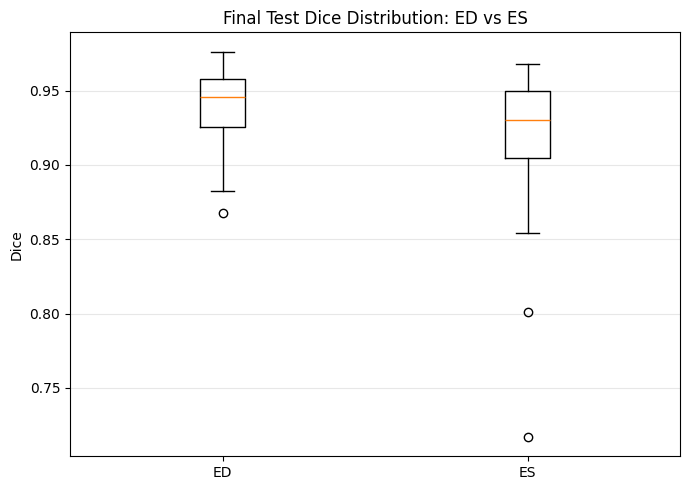

/tmp/ipykernel_1903/3741860173.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


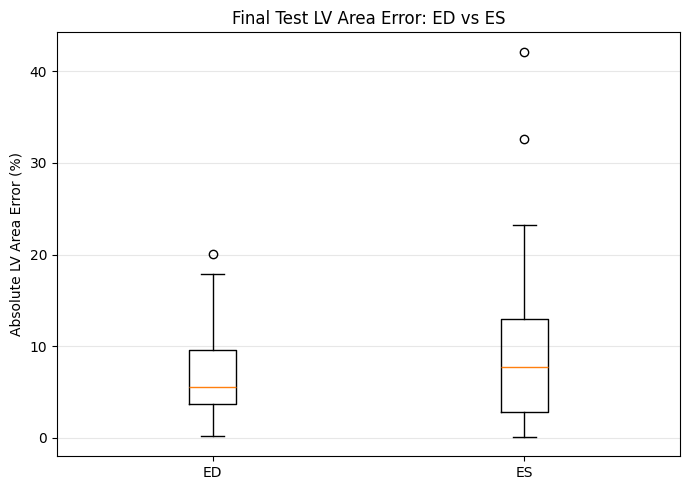

/tmp/ipykernel_1903/3741860173.py:94: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


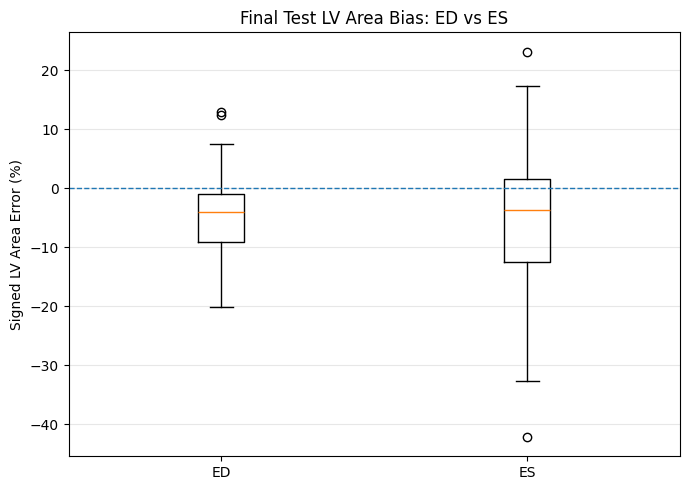

✓ Final distribution plots saved.


In [ ]:
# ================================================================
# PHASE 1E — CELL 19
# FINAL METRIC DISTRIBUTION PLOTS
# ================================================================

# ---------------- DICE ----------------

plt.figure(figsize=(7, 5))

plt.boxplot(
    [
        ed_test["dice"].values,
        es_test["dice"].values
    ],
    labels=["ED", "ES"]
)

plt.ylabel("Dice")
plt.title(
    "Final Test Dice Distribution: ED vs ES"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

DICE_PLOT_PATH = (
    P1E_PLOT_DIR /
    "test_dice_ED_vs_ES.png"
)

plt.savefig(
    DICE_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ---------------- AREA ERROR ----------------

plt.figure(figsize=(7, 5))

plt.boxplot(
    [
        ed_test[
            "abs_area_error_pct"
        ].values,

        es_test[
            "abs_area_error_pct"
        ].values
    ],
    labels=["ED", "ES"]
)

plt.ylabel(
    "Absolute LV Area Error (%)"
)

plt.title(
    "Final Test LV Area Error: ED vs ES"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

AREA_PLOT_PATH = (
    P1E_PLOT_DIR /
    "test_area_error_ED_vs_ES.png"
)

plt.savefig(
    AREA_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ---------------- SIGNED AREA ERROR ----------------

plt.figure(figsize=(7, 5))

plt.boxplot(
    [
        ed_test[
            "signed_area_error_pct"
        ].values,

        es_test[
            "signed_area_error_pct"
        ].values
    ],
    labels=["ED", "ES"]
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.ylabel(
    "Signed LV Area Error (%)"
)

plt.title(
    "Final Test LV Area Bias: ED vs ES"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

BIAS_PLOT_PATH = (
    P1E_PLOT_DIR /
    "test_signed_area_error_ED_vs_ES.png"
)

plt.savefig(
    BIAS_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("✓ Final distribution plots saved.")

In [ ]:
# ================================================================
# PHASE 1E — CELL 20
# OFFICIAL FINAL VALIDATION RECORD
# ================================================================

phase1e_final_record = {

    "phase":
        "Phase 1E — Final Segmentation Validation",

    "status":
        "COMPLETED",

    "model_selection_complete_before_test":
        True,

    "retraining_performed":
        False,

    "test_driven_tuning_performed":
        False,

    "final_configuration": {

        "resolution":
            256,

        "architecture":
            "Large U-Net",

        "filters":
            [32, 64, 128, 256, 512],

        "parameters":
            7_759_521,

        "optimizer":
            "Adam",

        "learning_rate":
            1e-4,

        "batch_size":
            2,

        "augmentation":
            False,

        "loss":
            "BCE + Dice",

        "threshold":
            0.50,

        "postprocessing":
            [
                "largest connected component",
                "binary hole filling"
            ]
    },

    "evaluation": {

        "patients":
            50,

        "frames":
            100,

        "ED_frames":
            50,

        "ES_frames":
            50
    },

    "final_test_results":
        {
            key: (
                float(value)
                if isinstance(
                    value,
                    (float, np.floating)
                )
                else int(value)
                if isinstance(
                    value,
                    (int, np.integer)
                )
                else value
            )
            for key, value
            in final_test_summary.items()
        },

    "distribution_findings": {

        "overall_dice_std":
            float(
                final_test_results[
                    "dice"
                ].std()
            ),

        "ED_dice_std":
            float(
                ed_test[
                    "dice"
                ].std()
            ),

        "ES_dice_std":
            float(
                es_test[
                    "dice"
                ].std()
            ),

        "overall_min_dice":
            float(
                final_test_results[
                    "dice"
                ].min()
            ),

        "ED_min_dice":
            float(
                ed_test[
                    "dice"
                ].min()
            ),

        "ES_min_dice":
            float(
                es_test[
                    "dice"
                ].min()
            ),

        "ED_frames_dice_below_0_90":
            int(
                (
                    ed_test["dice"] < 0.90
                ).sum()
            ),

        "ES_frames_dice_below_0_90":
            int(
                (
                    es_test["dice"] < 0.90
                ).sum()
            ),

        "ED_frames_area_error_above_20pct":
            int(
                (
                    ed_test[
                        "abs_area_error_pct"
                    ] > 20
                ).sum()
            ),

        "ES_frames_area_error_above_20pct":
            int(
                (
                    es_test[
                        "abs_area_error_pct"
                    ] > 20
                ).sum()
            )
    },

    "interpretation": (
        "The final configuration retained strong segmentation "
        "performance on the locked test evaluation, with only a "
        "modest reduction relative to validation. ES remained more "
        "challenging than ED, showing lower mean Dice, greater "
        "variability, and more high-area-error cases. The final test "
        "predictions also showed a negative signed LV area bias, "
        "indicating a tendency toward under-segmentation. No "
        "post-test correction or additional tuning was performed."
    ),

    "historical_test_exposure_limitation": (
        "The 50-patient test partition had been inspected during "
        "earlier pilot development before the clean Phase 1 rebuild. "
        "It was not used during clean Phase 1A-1D model selection. "
        "Therefore these results represent the locked final evaluation "
        "of the clean pipeline, but are not claimed to constitute a "
        "pristine never-inspected external or independent test set."
    ),

    "decision":
        (
            "Accept the selected segmentation configuration and "
            "freeze it for downstream quantitative LV analysis."
        ),

    "next_stage":
        "Phase 1F — Freeze Final Segmentation Model"
}


FINAL_RECORD_PATH = (
    P1E_CONFIG_DIR /
    "phase1E_final_validation_record.json"
)


with open(
    FINAL_RECORD_PATH,
    "w"
) as f:

    json.dump(
        phase1e_final_record,
        f,
        indent=2
    )


print("=" * 70)
print("PHASE 1E COMPLETED")
print("=" * 70)

print("\nFINAL TEST PERFORMANCE")

print(
    f"Overall Dice       : "
    f"{final_test_summary['overall_dice']:.4f}"
)

print(
    f"ED Dice            : "
    f"{final_test_summary['ED_dice']:.4f}"
)

print(
    f"ES Dice            : "
    f"{final_test_summary['ES_dice']:.4f}"
)

print(
    f"Overall IoU        : "
    f"{final_test_summary['overall_iou']:.4f}"
)

print(
    f"Normalized HD95    : "
    f"{final_test_summary['normalized_hd95']:.4f}"
)

print(
    f"Overall Area MAE   : "
    f"{final_test_summary['overall_area_MAE_pct']:.2f}%"
)

print(
    f"Overall Area Bias  : "
    f"{final_test_summary['overall_signed_area_error_pct']:+.2f}%"
)

print("\nDECISION:")
print(
    "Final segmentation configuration ACCEPTED."
)

print(
    "No post-test tuning will be performed."
)

print("\nSaved:")
print(FINAL_RECORD_PATH)

print(
    "\nNEXT: Phase 1F — "
    "Freeze Final Segmentation Model"
)

PHASE 1E COMPLETED

FINAL TEST PERFORMANCE
Overall Dice       : 0.9292
ED Dice            : 0.9396
ES Dice            : 0.9189
Overall IoU        : 0.8700
Normalized HD95    : 0.0256
Overall Area MAE   : 8.18%
Overall Area Bias  : -4.68%

DECISION:
Final segmentation configuration ACCEPTED.
No post-test tuning will be performed.

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/configs/phase1E_final_validation_record.json

NEXT: Phase 1F — Freeze Final Segmentation Model
